<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 150  Features: 4  Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'] 

Train size: 120  Test size: 30 

Class             Prior   Mean of the 4 features
Iris-setosa       0.358   [4.99, 3.43, 1.47, 0.25]
Iris-versicolor   0.325   [5.92, 2.77, 4.26, 1.34]
Iris-virginica    0.317   [6.61, 2.98, 5.55, 2.05]

Confusion Matrix (rows = actual, columns = predicted):
                 Iris-setosa  Iris-versicolor  Iris-virginica
Iris-setosa                7                0               0
Iris-versicolor            0               10               1
Iris-virginica             0                1              11

Accuracy: 93.33%

Class             Precision  Recall
Iris-setosa       1.00       1.00
Iris-versicolor   0.91       0.91
Iris-virginica    0.92       0.92

New flower (sepal_length, sepal_width, petal_length, petal_width): [5.9, 3.0, 5.1, 1.8]
  P(Iris-setosa) = 0.000
  P(Iris-versicolor) = 0.115
  P(Iris-virginica) = 0.885
Predicted species: Iris-virginica


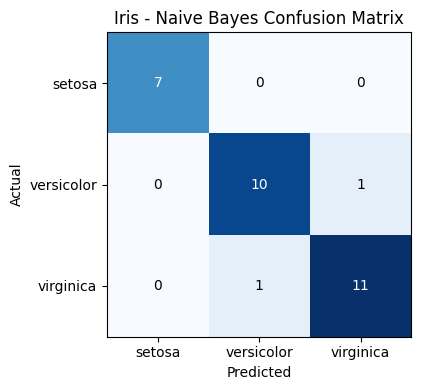

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: Iris - UCI Machine Learning Repository (program15.csv, used as it is, no header row)

# ---- 1. Load CSV ----
cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv('program15.csv', header=None, names=cols)
X = df.iloc[:, :-1].values.astype(float)
y = df['species'].values
classes = sorted(set(y))
print("Rows:", len(df), " Features:", X.shape[1], " Classes:", classes, "\n")

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
Xtr, Xte = X[idx[:split]], X[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]
print("Train size:", len(Xtr), " Test size:", len(Xte), "\n")

# ---- 3. Training: learn prior, mean and variance of each class ----
prior, mean, var = {}, {}, {}
print("Class             Prior   Mean of the 4 features")
for c in classes:
    Xc = Xtr[ytr == c]
    prior[c] = len(Xc) / len(Xtr)          # P(class)
    mean[c] = Xc.mean(axis=0)              # mean of each feature
    var[c] = Xc.var(axis=0) + 1e-9         # variance of each feature
    print(f"{c:<17} {prior[c]:.3f}   {np.round(mean[c], 2).tolist()}")

# ---- 4. Gaussian probability (in log form) ----
def log_gaussian(x, m, v):
    return -0.5 * np.log(2 * np.pi * v) - ((x - m) ** 2) / (2 * v)

# ---- 5. Prediction: P(class) x P(x1|class) x P(x2|class) ... ----
def class_scores(x):
    return {c: np.log(prior[c]) + np.sum(log_gaussian(x, mean[c], var[c])) for c in classes}

def predict(x):
    s = class_scores(x)
    return max(s, key=s.get)

preds = np.array([predict(x) for x in Xte])

# ---- 6. Confusion matrix ----
n = len(classes)
cm = np.zeros((n, n), dtype=int)
for a, p in zip(yte, preds):
    cm[classes.index(a), classes.index(p)] += 1

print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=classes, columns=classes))

# ---- 7. Accuracy, precision, recall ----
print(f"\nAccuracy: {np.trace(cm) / cm.sum() * 100:.2f}%")
print("\nClass             Precision  Recall")
for i, c in enumerate(classes):
    precision = cm[i, i] / cm[:, i].sum() if cm[:, i].sum() else 0
    recall = cm[i, i] / cm[i, :].sum() if cm[i, :].sum() else 0
    print(f"{c:<17} {precision:.2f}       {recall:.2f}")

# ---- 8. Classify a new flower ----
new_flower = np.array([5.9, 3.0, 5.1, 1.8])              # cm
s = class_scores(new_flower)
top = np.array(list(s.values()))
prob = np.exp(top - top.max()); prob = prob / prob.sum()  # convert scores to probabilities
print("\nNew flower (sepal_length, sepal_width, petal_length, petal_width):", new_flower.tolist())
for c, p in zip(classes, prob):
    print(f"  P({c}) = {p:.3f}")
print("Predicted species:", predict(new_flower))

# ---- 9. Plot the confusion matrix ----
short = [c.replace('Iris-', '') for c in classes]
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(n)); ax.set_xticklabels(short)
ax.set_yticks(range(n)); ax.set_yticklabels(short)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title('Iris - Naive Bayes Confusion Matrix')
for i in range(n):
    for j in range(n):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()